# 07 — Customer Segmentation (K-Means), Retention and Inactivity

## Purpose
Notebook 06 built validated RFM segments. This notebook asks three further questions:
1. Does an **unsupervised segmentation** (K-Means) find structure beyond the rule-based RFM segments?
2. How do acquisition **cohorts** retain? This reuses and validates the dbt mart `mart_customer_cohorts`.
3. Can customer **inactivity** support a meaningful churn definition?

## Rules
- **Customers and money:** a customer is `customer_unique_id` (D-01), and money is item revenue (Q-03).
- **No leakage:** clustering features use only orders as of the reference date **2018-08-31** (delivered scope), which is the same population as the approved `customer_rfm` query.
- **Cohorts:** the dbt mart is read from PostgreSQL, not rebuilt, and validated cell by cell against an independent computation from Gold.

*Running requires the project PostgreSQL database.*

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.database.connection import get_engine
from src.database.queries import run_query

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = ROOT / "reports" / "customer_analytics" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
REFERENCE_DATE, SEED = "2018-08-31", 42
ref = pd.Timestamp(REFERENCE_DATE)

GOLD = ROOT / "data" / "processed" / "analytical"
orders = pd.read_parquet(GOLD / "fact_orders.parquet")
customers = pd.read_parquet(GOLD / "dim_customers.parquet")
engine = get_engine()
rfm = run_query("customer_rfm", engine=engine, params={"reference_date": REFERENCE_DATE, "order_scope": "delivered"})
rfm = rfm[rfm["has_eligible_purchase"]].copy()
rfm["monetary"] = rfm["monetary"].astype(float)
print(f"RFM persons as of {REFERENCE_DATE}: {len(rfm):,}")

RFM persons as of 2018-08-31: 93,293


## 1. K-Means segmentation
### 1.1 Features
Each feature is one value per person, aggregated from that person's eligible orders, the same orders as in RFM, so there's no fan-out:

| Feature | Transform | Why |
|---|---|---|
| recency (days) | log1p | right-skewed |
| frequency (orders) | log1p | nearly binary (1 vs 2+), compressed so it can't dominate the distances |
| monetary (item revenue) | log1p | heavy tail (notebook 05) |
| freight share of order value | none (bounded 0–1) | logistics and price profile |
| average instalments | log1p | payment behaviour; one record with no payment data is set to 1 instalment |

All features are standardised (z-scores). K-Means uses Euclidean distance, so unscaled features with large ranges would dominate.

In [2]:
el = orders[orders["has_items"] & (orders["purchase_date"] <= ref) & (orders["order_status"] == "delivered")
            & (orders["order_delivered_customer_date"].dt.normalize() <= ref)]
beh = el.groupby("customer_unique_id").agg(price=("items_price_total", "sum"), freight=("items_freight_total", "sum"),
                                          avg_installments=("max_installments", "mean"))
beh["freight_share"] = beh["freight"] / (beh["price"] + beh["freight"])
n_no_inst = int(beh["avg_installments"].isna().sum())
beh["avg_installments"] = beh["avg_installments"].fillna(1.0)
feat = rfm.merge(beh.reset_index(), on="customer_unique_id", validate="1:1")
assert len(feat) == len(rfm) and np.allclose(feat["price"], feat["monetary"])          # same orders as RFM
X_raw = pd.DataFrame({"log_recency": np.log1p(feat["recency_days"]), "log_frequency": np.log1p(feat["frequency"]),
                      "log_monetary": np.log1p(feat["monetary"]), "freight_share": feat["freight_share"],
                      "log_installments": np.log1p(feat["avg_installments"])})
print(f"persons {len(feat):,} | missing instalments set to 1: {n_no_inst}")
display(X_raw.describe().T[["mean", "std", "min", "50%", "max"]])
display(X_raw.corr().round(2))
X = StandardScaler().fit_transform(X_raw)

persons 93,293 | missing instalments set to 1: 3


,mean,std,min,50%,max
log_recency,5.183,0.909,1.099,5.403,6.574
log_frequency,0.706,0.077,0.693,0.693,2.773
log_monetary,4.486,0.923,0.615,4.508,9.506
freight_share,0.208,0.125,0.000,0.183,0.955
log_installments,1.182,0.571,0.693,1.099,3.219


,log_recency,log_frequency,log_monetary,freight_share,log_installments
log_recency,1.000,-0.020,-0.000,-0.010,0.040
log_frequency,-0.020,1.000,0.150,-0.010,0.030
log_monetary,-0.000,0.150,1.000,-0.750,0.400
freight_share,-0.010,-0.010,-0.750,1.000,-0.260
log_installments,0.040,0.030,0.400,-0.260,1.000


### 1.2 Choosing the number of clusters
- **Range:** k = 2 to 8, each with 10 initialisations and a fixed seed.
- **Criteria:**
  - inertia (elbow);
  - silhouette, on a fixed random sample of 15,000 people, because the full calculation is quadratic in the number of people;
  - Davies–Bouldin (lower is better).
- **Choice:** the k with the best silhouette, accepted only if the other criteria and the cluster profiles agree.

,inertia,silhouette,davies_bouldin,smallest cluster share
k,,,,
2,"350,176.829",0.247,1.478,0.452
3,"264,859.024",0.281,1.117,0.030
4,"211,547.603",0.276,1.126,0.030
5,"170,603.634",0.301,0.987,0.030
6,"152,533.567",0.259,1.072,0.030
7,"137,266.736",0.263,1.048,0.030
8,"127,197.491",0.267,1.067,0.030


best silhouette: k = 5 (0.301); best Davies-Bouldin: k = 5


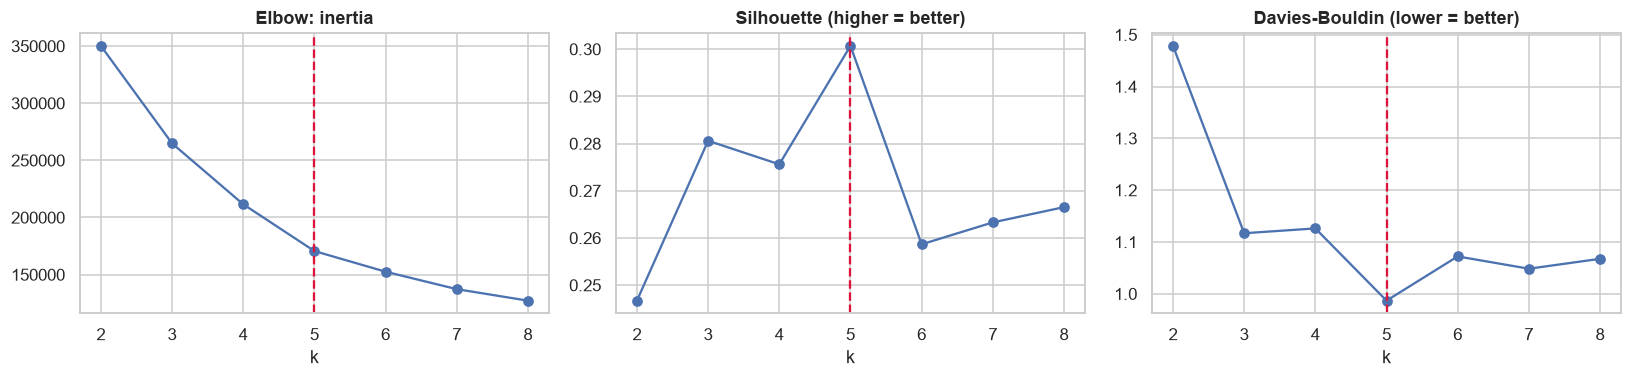

In [3]:
sel = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    sel.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_, sample_size=15_000, random_state=SEED),
                "davies_bouldin": davies_bouldin_score(X, km.labels_), "smallest cluster share": np.bincount(km.labels_).min() / len(X)})
sel = pd.DataFrame(sel).set_index("k")
display(sel)
K = int(sel["silhouette"].idxmax())
print(f"best silhouette: k = {K} ({sel.loc[K, 'silhouette']:.3f}); best Davies-Bouldin: k = {int(sel['davies_bouldin'].idxmin())}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, col, title in zip(ax, ("inertia", "silhouette", "davies_bouldin"), ("Elbow: inertia", "Silhouette (higher = better)", "Davies-Bouldin (lower = better)")):
    a.plot(sel.index, sel[col], marker="o"); a.axvline(K, color="crimson", ls="--"); a.set(title=title, xlabel="k")
plt.tight_layout(); plt.savefig(FIG / "kmeans_selection.png", bbox_inches="tight"); plt.show()

**Choice of k.**
- **The criteria agree:** silhouette is highest at **k = 5** (0.301), and Davies–Bouldin is lowest at k = 5 (0.987). The elbow is gradual, not sharp: inertia falls 20% from k = 3 to 4, 19% from 4 to 5 and 11% from 5 to 6, so the choice rests mainly on silhouette and Davies–Bouldin.
- **k = 5 is therefore supported by the evidence, not chosen in advance.**
- **The structure is moderate:** a silhouette of 0.30 means the clusters are reasonable, but not sharply separated. They're useful partitions of a continuum more than "natural types".
- **From k = 3 onwards** a 3% cluster appears. That's the repeat buyers, separated by the frequency feature.
- **Feature correlations:** monetary and freight share correlate strongly (−0.75), because freight is a smaller share of larger baskets, and monetary also correlates with instalments (0.40). Recency is uncorrelated with all the others.

### 1.3 Final model, stability and cluster profiles

stability across 5 other seeds: adjusted Rand index min 0.991, mean 0.994


,customers,median_recency_days,repeat_share,mean_orders,median_monetary,median_freight_share,median_installments,revenue,customer_share,revenue_share
cluster,,,,,,,,,,
0,22447,259.000,0.000,1.000,169.900,0.117,6.000,"5,894,996.510",0.241,0.446
1,34218,264.000,0.000,1.000,98.900,0.157,1.000,"4,459,617.430",0.367,0.338
3,12997,35.000,0.000,1.000,80.970,0.193,1.000,"1,452,571.300",0.139,0.110
4,2799,201.000,1.000,2.114,182.100,0.179,2.500,"727,855.230",0.030,0.055
2,20832,238.000,0.000,1.000,29.000,0.358,1.000,"673,464.020",0.223,0.051


,log_recency,log_frequency,log_monetary,freight_share,log_installments
cluster (centre in z-scores),,,,,
0,0.270,-0.170,0.790,-0.620,1.370
1,0.380,-0.170,0.160,-0.400,-0.570
2,0.240,-0.170,-1.200,1.360,-0.440
3,-1.830,-0.170,-0.050,-0.040,-0.200
4,-0.090,5.500,0.820,-0.080,0.190


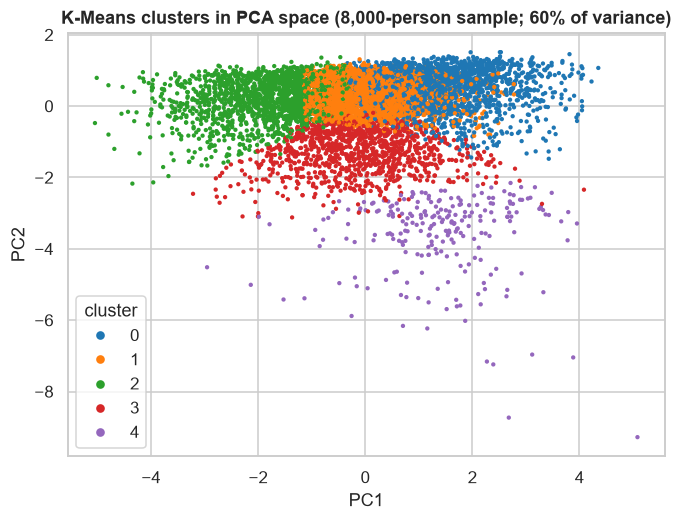

PCA explained variance (PC1, PC2): [0.398 0.205]


In [4]:
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
stability = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit(X).labels_) for s in range(5)]
print(f"stability across 5 other seeds: adjusted Rand index min {min(stability):.3f}, mean {np.mean(stability):.3f}")

feat["cluster"] = km.labels_
prof = feat.groupby("cluster").agg(customers=("customer_unique_id", "size"), median_recency_days=("recency_days", "median"),
                                   repeat_share=("frequency", lambda f: (f > 1).mean()), mean_orders=("frequency", "mean"),
                                   median_monetary=("monetary", "median"), median_freight_share=("freight_share", "median"),
                                   median_installments=("avg_installments", "median"), revenue=("monetary", "sum"))
prof["customer_share"] = prof["customers"] / prof["customers"].sum()
prof["revenue_share"] = prof["revenue"] / prof["revenue"].sum()
display(prof.sort_values("revenue_share", ascending=False))
centres = pd.DataFrame(km.cluster_centers_, columns=X_raw.columns).round(2)
centres.index.name = "cluster (centre in z-scores)"
display(centres)

pts = np.random.default_rng(SEED).choice(len(X), 8_000, replace=False)
pc = PCA(n_components=2, random_state=SEED).fit(X)
xy = pc.transform(X[pts])
plt.figure(figsize=(7, 5))
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=km.labels_[pts], palette="tab10", s=8, linewidth=0)
plt.title(f"K-Means clusters in PCA space (8,000-person sample; {pc.explained_variance_ratio_.sum():.0%} of variance)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(title="cluster", markerscale=2); plt.show()
print("PCA explained variance (PC1, PC2):", pc.explained_variance_ratio_.round(3))

**Cluster profiles.** The solution is very stable: the adjusted Rand index is at least 0.991 across five other seeds. The two principal components explain 60% of the variance (PC1 40%, PC2 21%).

| Cluster | Name (from profile) | Customers | Item revenue | Profile |
|---|---|---|---|---|
| 0 | **High-value instalment buyers** | 24.1% | **44.6%** | median 170 BRL, 6 instalments, low freight share (12%) |
| 1 | **Mid-value single-payment buyers** | 36.7% | 33.8% | median 99 BRL, 1 instalment, freight 16% |
| 3 | **Recent first-time buyers** | 13.9% | 11.0% | last purchase a median 35 days ago, average value |
| 4 | **Repeat buyers** | 3.0% | 5.5% | every member has 2+ orders (2.1 on average), median 182 BRL |
| 2 | **Low-value, freight-heavy buyers** | 22.3% | 5.1% | median 29 BRL; freight is 36% of order value |

The names describe the cluster centres (z-scores in the table above) and carry no other assumptions.

**Business meaning:**
- **Revenue depends on buyers who pay in instalments:** cluster 0, a quarter of customers, brings 45% of item revenue. Instalment availability and credit terms are commercially central.
- **About a fifth of customers buy cheap items where freight is over a third of the price** (cluster 2). They're a candidate group for free-shipping thresholds or bundling.

### 1.4 K-Means vs rule-based RFM segments

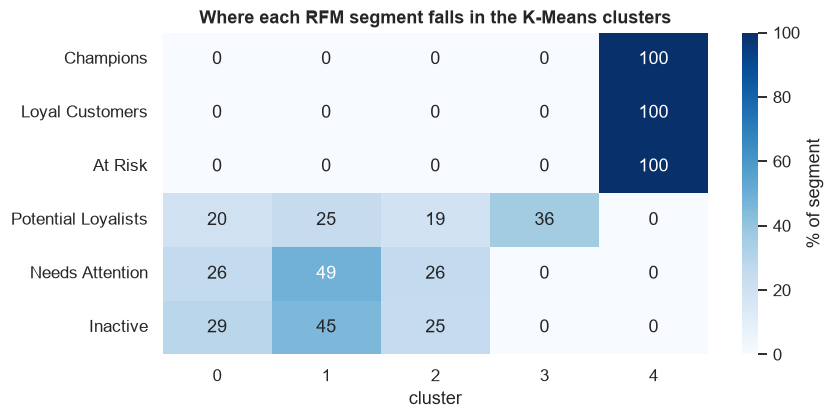

adjusted Rand index (K-Means vs RFM segments) = 0.091


cluster,0,1,2,3,4
segment,,,,,
Champions,0.000,0.000,0.000,0.000,100.000
Loyal Customers,0.000,0.000,0.000,0.000,100.000
At Risk,0.000,0.000,0.000,0.000,100.000
Potential Loyalists,19.900,24.700,19.300,36.000,0.000
Needs Attention,25.600,48.600,25.800,0.000,0.000
Inactive,29.200,45.400,25.400,0.000,0.000


In [5]:
SEGMENTS = ["Champions", "Loyal Customers", "At Risk", "Potential Loyalists", "Needs Attention", "Inactive"]
repeat = feat["frequency"] >= 2
rules = {"Champions": repeat & (feat["r_score"] >= 4) & (feat["m_score"] >= 4),
         "Loyal Customers": repeat & (feat["r_score"] >= 3) & ~((feat["r_score"] >= 4) & (feat["m_score"] >= 4)),
         "At Risk": repeat & (feat["r_score"] <= 2), "Potential Loyalists": ~repeat & (feat["r_score"] >= 4),
         "Needs Attention": ~repeat & (feat["r_score"] == 3), "Inactive": ~repeat & (feat["r_score"] <= 2)}
assert (pd.DataFrame(rules).sum(axis=1) == 1).all()           # same definitions as notebook 06
feat["segment"] = pd.Categorical(pd.DataFrame(rules).idxmax(axis=1), categories=SEGMENTS, ordered=True)
ct = pd.crosstab(feat["segment"], feat["cluster"], normalize="index")
plt.figure(figsize=(8, 3.8))
sns.heatmap(ct * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of segment"})
plt.title("Where each RFM segment falls in the K-Means clusters"); plt.ylabel(""); plt.show()
print(f"adjusted Rand index (K-Means vs RFM segments) = {adjusted_rand_score(feat['segment'], feat['cluster']):.3f}")
display((ct * 100).round(1))

**K-Means vs RFM** (adjusted Rand index 0.091, low agreement):
- **They agree on repeat buying:** all three repeat RFM segments (Champions, Loyal Customers, At Risk) fall 100% into cluster 4.
- **They disagree on one-time buyers, which are 97% of customers:**
  - RFM splits them **by recency** (Potential Loyalists, Needs Attention, Inactive).
  - K-Means splits them **by value and payment profile.** Only the most recent part of the Potential Loyalists (36%) forms a cluster of its own (3); the rest spread across clusters 0–2 in similar proportions.

**Practical conclusion:** the two segmentations are **complementary, not competing**.
- **RFM answers "who to contact now"** (recency).
- **K-Means answers "what kind of buyer"** (basket value, instalments, freight sensitivity).

A campaign can combine them, for example recent first-time buyers who are high-value instalment buyers.

## 2. Retention and acquisition cohorts
### 2.1 Validate the dbt mart against an independent computation
`dbt_marts.mart_customer_cohorts` has the grain cohort month × months since first purchase. It uses all orders of any status, with the cohort defined as Gold `dim_customers.cohort_month`.

The independent check below recomputes each person's cohort from their earliest order timestamp in `fact_orders`, then counts active customers, orders and item revenue per cell.

In [6]:
with engine.connect() as c:
    mart = pd.read_sql(text("SELECT * FROM dbt_marts.mart_customer_cohorts"), c)
first = orders.groupby("customer_unique_id")["order_purchase_timestamp"].min().dt.to_period("M")
o = orders.assign(cohort=orders["customer_unique_id"].map(first), activity=orders["order_purchase_timestamp"].dt.to_period("M"))
o["k"] = (o["activity"] - o["cohort"]).apply(lambda d: d.n)
mine = o.groupby(["cohort", "k"]).agg(active=("customer_unique_id", "nunique"), n_orders=("order_id", "size"),
                                      items=("items_price_total", "sum"))
mine.index = pd.MultiIndex.from_arrays([mine.index.get_level_values(0).astype(str), mine.index.get_level_values(1)])
size = first.astype(str).value_counts()
m = mart.set_index(["cohort_month", "months_since_first_purchase"])
active_cells = m[m["active_customers"] > 0]
checks = {
    "cohort months match dim_customers": bool((customers.set_index("customer_unique_id")["cohort_month"] == first.astype(str)).all()),
    "same non-empty cells": set(active_cells.index) == set(mine.index),
    "active customers": bool((active_cells["active_customers"] == mine.loc[active_cells.index, "active"]).all()),
    "orders": bool((active_cells["n_orders"] == mine.loc[active_cells.index, "n_orders"]).all()),
    "item revenue": bool(np.allclose(active_cells["items_price_total"].astype(float), mine.loc[active_cells.index, "items"].round(2))),
    "cohort sizes": bool((m.xs(0, level=1)["cohort_size"] == size.reindex(m.xs(0, level=1).index)).all()),
    "retention_pct": bool(np.allclose(m["retention_pct"].astype(float), (100 * m["active_customers"] / m["cohort_size"]).round(4))),
}
print(f"mart cells {len(mart)} (non-empty {len(active_cells)}) | independent cells {len(mine)}"); print(checks)
assert all(checks.values())

mart cells 327 (non-empty 225) | independent cells 225
{'cohort months match dim_customers': True, 'same non-empty cells': True, 'active customers': True, 'orders': True, 'item revenue': True, 'cohort sizes': True, 'retention_pct': True}


### 2.2 Cohort retention heatmap (cohorts and activity months inside the Q-11 window)

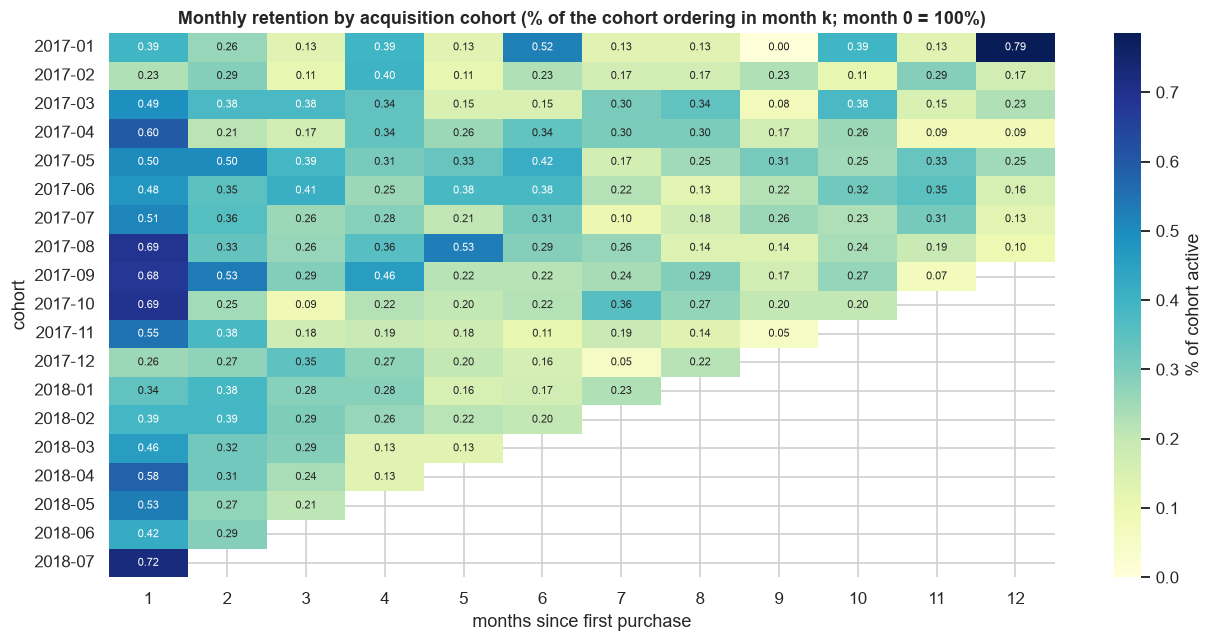

months_since_first_purchase,1,2,3,4,5,6,7,8,9,10,11,12
active_customers,453.000,285.000,202.000,185.000,143.000,132.000,106.000,92.000,64.000,79.000,58.000,40.000
cohort_size,"89,493.000","83,422.000","77,482.000","70,860.000","64,149.000","57,184.000","50,733.000","43,708.000","38,221.000","30,917.000","26,447.000","22,317.000"
pooled_retention_pct,0.506,0.342,0.261,0.261,0.223,0.231,0.209,0.210,0.167,0.256,0.219,0.179


cohort month-1 retention: min 0.23%, median 0.50%, max 0.72% (2017-02 / 2018-07)


In [7]:
win = mart[mart["cohort_in_candidate_window"] & mart["activity_in_candidate_window"]
           & mart["months_since_first_purchase"].between(1, 12)]
heat = win.pivot(index="cohort_month", columns="months_since_first_purchase", values="retention_pct").astype(float)
plt.figure(figsize=(12, 6))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlGnBu", annot_kws={"size": 7}, cbar_kws={"label": "% of cohort active"})
plt.title("Monthly retention by acquisition cohort (% of the cohort ordering in month k; month 0 = 100%)")
plt.xlabel("months since first purchase"); plt.ylabel("cohort")
plt.tight_layout(); plt.savefig(FIG / "cohort_heatmap.png", bbox_inches="tight"); plt.show()

pooled = win.groupby("months_since_first_purchase")[["active_customers", "cohort_size"]].sum()
pooled["pooled_retention_pct"] = 100 * pooled["active_customers"] / pooled["cohort_size"]
display(pooled.T.round(3))
print(f"cohort month-1 retention: min {heat[1].min():.2f}%, median {heat[1].median():.2f}%, max {heat[1].max():.2f}% "
      f"({heat[1].idxmin()} / {heat[1].idxmax()})")

**Validation.** The dbt mart matches the independent recomputation exactly. That covers all 225 non-empty cells (active customers, orders, item revenue), every cohort size, the retention percentages, and the cohort month itself, which agrees with Gold `dim_customers` for every person. The remaining 102 mart cells are the explicit zero months. Nothing was rebuilt.

**Retention is very low and remarkably flat:**
- **Monthly retention:** in the month after acquisition, only **0.51%** of a cohort (pooled) buys again. After that, monthly retention settles at about **0.2–0.3%**, and it is still about 0.18% at 12 months.
- **No cohort stands out:** month-1 retention ranges only from 0.23% (2017-02) to 0.72% (2018-07), with a median of 0.50%. Cohort quality didn't change much as the business grew.

There's no early drop-off followed by a loyal core, which is the shape typical of subscription businesses. Instead, a small, near-constant trickle of repurchases continues over time. In this marketplace a second purchase is an occasional event, not a habit.

## 3. Inactivity and churn: what the data can support
**Question:** after how long without a purchase is a customer's return unlikely enough to call them *inactive*?

- **Method:** a Kaplan–Meier estimate of the time from a person's first purchase to their **second purchase**.
- **Second purchase:** an order at least 1 day after the first. Same-day orders are treated as split baskets (Q-09).
- **Censoring:** people who haven't bought again by the reference date are right-censored there. No information after 2018-08-31 is used, so there's no leakage.
- **What the estimate gives:** the cumulative probability of returning within t days, F(t) = 1 − S(t), where S(t) is the probability of not having returned yet.

persons 96,090 | observed second purchases 2,112 | horizon with >= 1,000 at risk: 578 days
cumulative repurchase probability F(t): 30 d: 0.65%, 90 d: 1.29%, 180 d: 1.92%, 365 d: 3.01%, 578 d: 3.78%
90% of the repurchases observed by day 578 happen within 458 days (horizon-dependent, see interpretation)


,P(return in next 180 days | none by d),persons still at risk at d
days without a second purchase (d),,
0,0.019,96090
30,0.015,89835
90,0.012,77290
180,0.011,57562
365,0.007,22034


as of 2018-08-31 (96,090 customers): no purchase for > 180 days 59.9%, > 365 days 22.8%


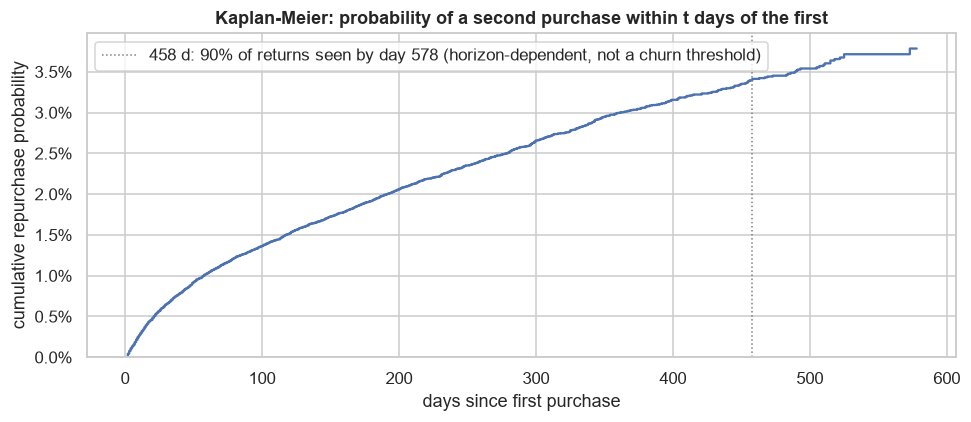

In [8]:
first_ts = orders.groupby("customer_unique_id")["order_purchase_timestamp"].min()
nxt = orders.assign(f=orders["customer_unique_id"].map(first_ts))
nxt = nxt[(nxt["order_purchase_timestamp"] - nxt["f"]).dt.total_seconds() >= 86_400]
second = nxt.groupby("customer_unique_id")["order_purchase_timestamp"].min()
pop = first_ts[first_ts <= ref + pd.Timedelta(days=1)]                        # first purchase on or before the reference date
t2 = second.reindex(pop.index)
event = t2.notna() & (t2 < ref + pd.Timedelta(days=1))
dur = np.where(event, (t2 - pop).dt.total_seconds() / 86_400, (ref + pd.Timedelta(days=1) - pop).dt.total_seconds() / 86_400)
km_df = pd.DataFrame({"t": np.ceil(dur).astype(int), "e": event.astype(int)})
g = km_df.groupby("t")["e"].agg(["sum", "size"]).sort_index()
at_risk = g["size"][::-1].cumsum()[::-1]
S = (1 - g["sum"] / at_risk).cumprod()
F = 1 - S
T_MAX = int(at_risk[at_risk >= 1000].index.max())                            # keep >= 1,000 persons at risk
F_max = float(F.loc[:T_MAX].iloc[-1])
t90 = int(F.index[F >= 0.9 * F_max][0])
print(f"persons {len(pop):,} | observed second purchases {int(event.sum()):,} | horizon with >= 1,000 at risk: {T_MAX} days")
print("cumulative repurchase probability F(t): " + ", ".join(f"{d} d: {float(F.loc[:d].iloc[-1]):.2%}" for d in (30, 90, 180, 365, T_MAX)))
print(f"90% of the repurchases observed by day {T_MAX} happen within {t90} days (horizon-dependent, see interpretation)")

# does inactivity make a return less likely? P(return within the next 180 days | no return for d days)
Fd = lambda d: float(F.loc[:d].iloc[-1]) if (F.index <= d).any() else 0.0      # F(0) = 0
cond = pd.DataFrame([{"days without a second purchase (d)": d, "P(return in next 180 days | none by d)": (Fd(d + 180) - Fd(d)) / (1 - Fd(d)),
                      "persons still at risk at d": int(at_risk.loc[d:].iloc[0])} for d in (0, 30, 90, 180, 365) if d + 180 <= T_MAX])
display(cond.set_index("days without a second purchase (d)"))

last = orders[orders["order_purchase_timestamp"] < ref + pd.Timedelta(days=1)].groupby("customer_unique_id")["order_purchase_timestamp"].max()
days_since = (ref + pd.Timedelta(days=1) - last).dt.days
print(f"as of {REFERENCE_DATE} ({len(last):,} customers): no purchase for > 180 days {(days_since > 180).mean():.1%}, > 365 days {(days_since > 365).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.step(F.loc[:T_MAX].index, F.loc[:T_MAX].values, where="post")
ax.axvline(t90, color="gray", ls=":", lw=1, label=f"{t90} d: 90% of returns seen by day {T_MAX} (horizon-dependent, not a churn threshold)")
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1)); ax.legend()
ax.set(title="Kaplan-Meier: probability of a second purchase within t days of the first", xlabel="days since first purchase",
       ylabel="cumulative repurchase probability")
plt.tight_layout(); plt.savefig(FIG / "repurchase_km.png", bbox_inches="tight"); plt.show()

**What the inactivity analysis shows:**
- **The return probability never plateaus.** The probability of a second purchase rises almost linearly: 0.65% within 30 days, 1.9% within 180 days, 3.0% within a year and 3.8% by day 578, the last day with at least 1,000 people at risk.
- **The "458 days" figure isn't a threshold.** It is where 90% of the returns observed *by day 578* have happened, and it would move with the horizon, so it shouldn't be used as a churn threshold.
- **Inactivity lowers the chance of a return, but only gradually, from a tiny base.** The probability of returning within the next 180 days falls from 1.9% at day 0 to 1.5% (30 days without a purchase), 1.2% (90), 1.1% (180) and 0.7% (365).

**Why no churn label is defined:**
1. **Non-return is the default.** Even a customer who bought yesterday has a 98% chance of not returning within 180 days, so a "churned" label would mostly reproduce the base rate, not a change in behaviour.
2. **Inactivity can't be confirmed as permanent.** The observation window is about 20 months, and late returns keep occurring at a near-constant low rate.
3. **There's no relationship to end.** Customers have no subscription to cancel, so "churn" would be an invented event.

**What can be reported:** as of 2018-08-31, 59.9% of customers haven't purchased for more than 180 days, and 22.8% for more than a year. These are **inactivity** shares, not churn rates.

**Business implication:** effort is better spent on the first weeks after a first purchase, when the return probability is highest, than on "win-back" campaigns built on an inactivity label.

## 4. Summary

| Area | Result | Implication |
|---|---|---|
| K-Means | k = 5 supported (silhouette 0.30, Davies–Bouldin 0.99, ARI ≥ 0.99 across seeds) | Moderate structure; useful partitions |
| Clusters | high-value instalment buyers 24% → 45% of revenue; low-value freight-heavy buyers 22% → 5%; repeat buyers 3% → 5.5% | Credit terms and freight policy matter commercially |
| K-Means vs RFM | same repeat group; otherwise value-based vs recency-based (ARI 0.09) | Combine: RFM for timing, K-Means for buyer type |
| Cohorts (dbt mart validated exactly) | month-1 retention 0.51% pooled; then 0.2–0.3% per month, flat | Repurchase is occasional, not habitual |
| Inactivity | return probability rises steadily, with no plateau; P(return in 180 days) 1.9% → 0.7% with inactivity | No defensible churn label; focus on the post-purchase window |

**Limitations:**
- **Clustering scope:** it uses five behavioural features as of 2018-08-31. Other choices (for example categories, region or reviews) would give a different, equally valid partition. The cluster names describe centres, not causes.
- **K-Means assumptions:** it favours compact, similarly sized groups, and a silhouette of 0.30 means the borders are soft.
- **Cohorts and inactivity:** both use all orders of any status (the mart's definition), while RFM uses delivered orders. The populations differ by design (96,090 vs 93,293 people).
- **Kaplan–Meier:** it covers only the first-to-second purchase, and same-day orders are treated as split baskets. Late cohorts have a short follow-up, which censoring handles but which still limits precision at long horizons.

In [9]:
engine.dispose()